# NSPPK Classifier Benchmark

Compare fast linear classifiers with Random Forest, ExtraTrees, and XGBoost on the local MoleculeNet HIV dataset. Every estimator uses the same cached 14-bit NSPPK features (`radius=1`, `distance=4`) at connector thicknesses `0` and `1`, across repeated stratified 70/30 splits.

Feature generation is timed separately from estimator fitting and prediction. Runtime plots use end-to-end training time (training feature generation plus estimator fit) against mean average precision. Short-run SGD candidates deliberately use only one or five passes, prioritizing speed over predictive performance.


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from rdkit import RDLogger
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedShuffleSplit

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / "src").exists())
SRC_DIR = REPO_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nsppk import NSPPK, NSPPKClassifier

DATASET_FILE = REPO_ROOT / "data" / "HIV.csv"
LIMIT = 8000
NBITS = 14
RADIUS = 1
DISTANCE = 4
CONNECTORS = (0, 1)
N_REPEATS = 3
RANDOM_STATE = 42
TEST_SIZE = 0.30

RDLogger.DisableLog("rdApp.*")


## Load the graph sample

The same fixed graph sample is reused for every connector setting, estimator, and split. With an 8,000-graph cap, `balance=True` may still return an imbalanced sample when the minority class is too small to balance all requested rows; the observed class rates are printed below.


In [2]:
loader = NSPPK(
    radius=RADIUS,
    distance=DISTANCE,
    connector=0,  # Graph loading is independent of the connector setting used by the classifiers.
    nbits=NBITS,
    dense=False,
    parallel=True,
)
graphs = loader.load_from(
    DATASET_FILE,
    "smiles",
    limit=LIMIT,
    random_state=RANDOM_STATE,
    balance=True,
    label_extractor=lambda graph: int(graph.graph["HIV_active"]),
)
y = np.asarray([int(graph.graph["HIV_active"]) for graph in graphs])

print(f"Dataset: {DATASET_FILE}")
print(f"Graphs: {len(graphs):,}")
print(f"Positive rate: {y.mean():.3f}")
print(f"Class counts: {dict(zip(*np.unique(y, return_counts=True)))}")


Dataset: /Users/f.costa/Documents/Projects/Repositories/ACTIVE/NSPPK/data/HIV.csv
Graphs: 8,000
Positive rate: 0.180
Class counts: {np.int64(0): np.int64(6557), np.int64(1): np.int64(1443)}


## Compare linear and tree classifiers

Linear candidates include one-epoch and five-epoch `Perceptron`, hinge-loss SGD, and logistic-loss SGD, plus `LogisticRegression(liblinear)` and `LinearSVC`. Tree baselines are 100-tree Random Forest and ExtraTrees models, plus 100-round XGBoost with histogram tree building. All models consume the same cached sparse feature matrices. The linear one-epoch SGD settings favor fit speed and may reduce predictive quality.


In [3]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, Perceptron, SGDClassifier
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, average_precision_score, balanced_accuracy_score

try:
    from xgboost import XGBClassifier
except ImportError:
    XGBClassifier = None

ESTIMATORS = {
    "Perceptron-1ep": lambda: Perceptron(
        penalty=None, alpha=0.0, max_iter=1, tol=None, shuffle=False,
        random_state=RANDOM_STATE,
    ),
    "Perceptron-5ep": lambda: Perceptron(
        penalty=None, alpha=0.0, max_iter=5, tol=None, shuffle=False,
        random_state=RANDOM_STATE,
    ),
    "SGD-hinge-1ep": lambda: SGDClassifier(
        loss="hinge", penalty=None, max_iter=1, tol=None, shuffle=False,
        learning_rate="constant", eta0=1.0, fit_intercept=False,
        random_state=RANDOM_STATE,
    ),
    "SGD-hinge-5ep": lambda: SGDClassifier(
        loss="hinge", penalty=None, max_iter=5, tol=None, shuffle=False,
        learning_rate="constant", eta0=1.0, fit_intercept=False,
        random_state=RANDOM_STATE,
    ),
    "SGD-logloss-1ep": lambda: SGDClassifier(
        loss="log_loss", penalty=None, max_iter=1, tol=None, shuffle=False,
        learning_rate="constant", eta0=1.0, fit_intercept=False,
        random_state=RANDOM_STATE,
    ),
    "SGD-logloss-5ep": lambda: SGDClassifier(
        loss="log_loss", penalty=None, max_iter=5, tol=None, shuffle=False,
        learning_rate="constant", eta0=1.0, fit_intercept=False,
        random_state=RANDOM_STATE,
    ),
    "Logistic-liblinear": lambda: LogisticRegression(
        C=0.01, class_weight="balanced", max_iter=2000, solver="liblinear",
    ),
    "LinearSVC": lambda: LinearSVC(
        C=0.01, class_weight="balanced", dual="auto", max_iter=2000,
        random_state=RANDOM_STATE,
    ),
    "RandomForest": lambda: RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "ExtraTrees": lambda: ExtraTreesClassifier(
        n_estimators=100,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
}
if XGBClassifier is not None:
    ESTIMATORS["XGBoost"] = lambda: XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        eval_metric="logloss",
        tree_method="hist",
        verbosity=0,
    )
else:
    print("XGBoost comparison skipped: install the optional xgboost package.")

splitter = StratifiedShuffleSplit(
    n_splits=N_REPEATS,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)
feature_sets = []
feature_timings = []
for repeat, (train_idx, test_idx) in enumerate(splitter.split(np.zeros(len(y)), y), start=1):
    train_graphs = [graphs[index] for index in train_idx]
    test_graphs = [graphs[index] for index in test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    for connector in CONNECTORS:
        encoder = NSPPK(
            radius=RADIUS,
            distance=DISTANCE,
            connector=connector,
            nbits=NBITS,
            dense=False,
            parallel=True,
        )
        feature_fit_start = time.perf_counter()
        encoder.fit(train_graphs, y_train)
        X_train = encoder.transform(train_graphs)
        feature_fit_seconds = time.perf_counter() - feature_fit_start

        feature_test_start = time.perf_counter()
        X_test = encoder.transform(test_graphs)
        feature_test_seconds = time.perf_counter() - feature_test_start
        feature_sets.append((repeat, connector, X_train, X_test, y_train, y_test))
        feature_timings.append({
            "repeat": repeat,
            "connector": connector,
            "feature_fit_seconds": feature_fit_seconds,
            "feature_test_transform_seconds": feature_test_seconds,
            "train_nnz": X_train.nnz,
            "test_nnz": X_test.nnz,
        })
        print(f"Cached features for repeat {repeat}/{N_REPEATS}, connector={connector}")

results = []
for repeat, connector, X_train, X_test, y_train, y_test in feature_sets:
    for name, estimator_factory in ESTIMATORS.items():
        # Warm up estimator code paths on a small balanced subset; time a fresh full fit.
        warm_indices = np.concatenate([
            np.flatnonzero(y_train == class_label)[:64]
            for class_label in np.unique(y_train)
        ])
        estimator_factory().fit(X_train[warm_indices], y_train[warm_indices])
        model = estimator_factory()
        fit_start = time.perf_counter()
        model.fit(X_train, y_train)
        fit_seconds = time.perf_counter() - fit_start

        predict_start = time.perf_counter()
        predictions = model.predict(X_test)
        predict_seconds = time.perf_counter() - predict_start

        score_start = time.perf_counter()
        if hasattr(model, "decision_function"):
            score_method = "decision_function"
            scores = model.decision_function(X_test)
        else:
            score_method = "predict_proba"
            positive_class_index = list(model.classes_).index(1)
            scores = model.predict_proba(X_test)[:, positive_class_index]
        score_seconds = time.perf_counter() - score_start

        results.append({
            "repeat": repeat,
            "connector": connector,
            "estimator": name,
            "score_method": score_method,
            "fit_seconds": fit_seconds,
            "predict_seconds": predict_seconds,
            "score_seconds": score_seconds,
            "accuracy": accuracy_score(y_test, predictions),
            "balanced_accuracy": balanced_accuracy_score(y_test, predictions),
            "average_precision": average_precision_score(y_test, scores),
            "n_iter": getattr(model, "n_iter_", np.nan),
        })

results_df = pd.DataFrame(results)
feature_timings_df = pd.DataFrame(feature_timings)
display(results_df.round(4))


Cached features for repeat 1/3, connector=0


Cached features for repeat 1/3, connector=1


Cached features for repeat 2/3, connector=0


Cached features for repeat 2/3, connector=1


Cached features for repeat 3/3, connector=0


Cached features for repeat 3/3, connector=1


... (3 outputs left out)

/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


/Users/f.costa/.venvs/py312/lib/python3.12/site-packages/sklearn/svm/_base.py:1295: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


,repeat,connector,estimator,score_method,fit_seconds,predict_seconds,score_seconds,accuracy,balanced_accuracy,average_precision,n_iter
0,1,0,Perceptron-1ep,decision_function,0.0166,0.0052,0.0019,0.3575,0.5702,0.4220,1
1,1,0,Perceptron-5ep,decision_function,0.0188,0.0020,0.0019,0.6538,0.7086,0.5703,5
2,1,0,SGD-hinge-1ep,decision_function,0.0065,0.0019,0.0018,0.3575,0.5702,0.4220,1
3,1,0,SGD-hinge-5ep,decision_function,0.0181,0.0019,0.0018,0.6538,0.7086,0.5703,5
4,1,0,SGD-logloss-1ep,decision_function,0.0066,0.0019,0.0019,0.3908,0.5887,0.4760,1
...,...,...,...,...,...,...,...,...,...,...,...
61,3,1,Logistic-liblinear,decision_function,3.6648,0.0047,0.0036,0.8533,0.7367,0.5974,[18]
62,3,1,LinearSVC,decision_function,10.3657,0.0037,0.0036,0.8371,0.7106,0.5447,2000
63,3,1,RandomForest,predict_proba,0.3222,0.0317,0.0403,0.8867,0.7300,0.6389,NaN
64,3,1,ExtraTrees,predict_proba,0.4865,0.0378,0.0312,0.8838,0.7057,0.6347,NaN


## Timing summary

Estimator timings below exclude graph feature generation; `feature_timings_df` reports that cost separately. `score_method` identifies the score source used for average precision: decision scores when available, otherwise positive-class probabilities. The final plot combines mean estimator fit time with mean training feature-generation time, then shows the nondominated performance/runtime choices.


In [4]:
summary = results_df.groupby(["connector", "estimator"]).agg({
    "fit_seconds": ["mean", "std"],
    "predict_seconds": ["mean", "std"],
    "score_seconds": ["mean", "std"],
    "accuracy": ["mean", "std"],
    "balanced_accuracy": ["mean", "std"],
    "average_precision": ["mean", "std"],
    "n_iter": "mean",
})
summary.round(4)


fit_seconds         predict_seconds          \
                                    mean     std            mean     std   
connector estimator                                                        
0         ExtraTrees              0.3353  0.0070          0.0287  0.0010   
          LinearSVC               5.6605  0.1875          0.0022  0.0004   
          Logistic-liblinear      2.3049  0.3165          0.0020  0.0001   
          Perceptron-1ep          0.0153  0.0018          0.0047  0.0005   
          Perceptron-5ep          0.0187  0.0004          0.0019  0.0000   
          RandomForest            0.2456  0.0092          0.0310  0.0001   
          SGD-hinge-1ep           0.0066  0.0001          0.0019  0.0000   
          SGD-hinge-5ep           0.0182  0.0001          0.0019  0.0000   
          SGD-logloss-1ep         0.0067  0.0002          0.0019  0.0000   
          SGD-logloss-5ep         0.0199  0.0010          0.0019  0.0000   
          XGBoost                 0.8854  0.0137          0.0031  0.0002   
1         ExtraTrees              0.4855  0.0009          0.0375  0.0058   
          LinearSVC              10.8185  0.3952          0.0036  0.0001   
          Logistic-liblinear      4.2058  0.5702          0.0041  0.0006   
          Perceptron-1ep          0.0257  0.0015          0.0089  0.0009   
          Perceptron-5ep          0.0354  0.0008          0.0037  0.0001   
          RandomForest            0.3287  0.0065          0.0348  0.0064   
          SGD-hinge-1ep           0.0124  0.0003          0.0036  0.0000   
          SGD-hinge-5ep           0.0347  0.0001          0.0037  0.0001   
          SGD-logloss-1ep         0.0125  0.0000          0.0036  0.0000   
          SGD-logloss-5ep         0.0356  0.0001          0.0036  0.0000   
          XGBoost                 1.2140  0.0380          0.0033  0.0000   

                             score_seconds         accuracy          \
                                      mean     std     mean     std   
connector estimator                                                   
0         ExtraTrees                0.0284  0.0004   0.8904  0.0055   
          LinearSVC                 0.0019  0.0000   0.8404  0.0037   
          Logistic-liblinear        0.0019  0.0000   0.8553  0.0062   
          Perceptron-1ep            0.0019  0.0000   0.6676  0.2686   
          Perceptron-5ep            0.0019  0.0000   0.7796  0.1090   
          RandomForest              0.0280  0.0023   0.8929  0.0047   
          SGD-hinge-1ep             0.0018  0.0000   0.6729  0.2733   
          SGD-hinge-5ep             0.0019  0.0000   0.7832  0.1122   
          SGD-logloss-1ep           0.0019  0.0000   0.6810  0.2513   
          SGD-logloss-5ep           0.0018  0.0000   0.7961  0.0959   
          XGBoost                   0.0029  0.0002   0.8921  0.0022   
1         ExtraTrees                0.0342  0.0059   0.8849  0.0023   
          LinearSVC                 0.0035  0.0000   0.8411  0.0077   
          Logistic-liblinear        0.0036  0.0001   0.8568  0.0033   
          Perceptron-1ep            0.0036  0.0001   0.8465  0.0096   
          Perceptron-5ep            0.0036  0.0000   0.8482  0.0244   
          RandomForest              0.0371  0.0052   0.8928  0.0053   
          SGD-hinge-1ep             0.0036  0.0000   0.8465  0.0096   
          SGD-hinge-5ep             0.0036  0.0000   0.8439  0.0340   
          SGD-logloss-1ep           0.0035  0.0000   0.8222  0.0205   
          SGD-logloss-5ep           0.0036  0.0000   0.8142  0.0640   
          XGBoost                   0.0031  0.0003   0.8886  0.0024   

                             balanced_accuracy         average_precision  \
                                          mean     std              mean   
connector estimator                                                        
0         ExtraTrees                    0.7245  0.0146            0.6739   
          LinearSVC                     0.7333  

In [5]:
feature_timings_df.groupby("connector").agg({
    "feature_fit_seconds": ["mean", "std"],
    "feature_test_transform_seconds": ["mean", "std"],
    "train_nnz": "mean",
    "test_nnz": "mean",
}).round(4)


feature_fit_seconds         feature_test_transform_seconds          \
                         mean     std                           mean     std   
connector                                                                      
0                      3.6550  0.1260                         2.1522  0.4315   
1                      5.4374  0.4225                         2.6408  0.2740   

              train_nnz      test_nnz  
                   mean          mean  
connector                              
0          4.438172e+06  1.892982e+06  
1          8.436880e+06  3.596665e+06

## Fastest linear estimator from this sweep

Use one-pass `SGDClassifier(loss="log_loss")` when estimator speed is the priority. Its mean cached-feature fit time was about 0.0066 s at connector 0 and 0.0124 s at connector 1; one-pass hinge SGD was effectively tied at connector 0 and slightly slower at connector 1. The model keeps `predict_proba()` support. This setting disables regularization and the intercept and performs one pass, so treat its predictions as speed-first.

```python
fast_linear = SGDClassifier(
    loss="log_loss",
    penalty=None,
    max_iter=1,
    tol=None,
    shuffle=False,
    learning_rate="constant",
    eta0=1.0,
    fit_intercept=False,
    random_state=RANDOM_STATE,
)
model = NSPPKClassifier(
    estimator=fast_linear,
    radius=RADIUS, distance=DISTANCE, connector=0,
    nbits=NBITS, dense=False, parallel=True,
)
```


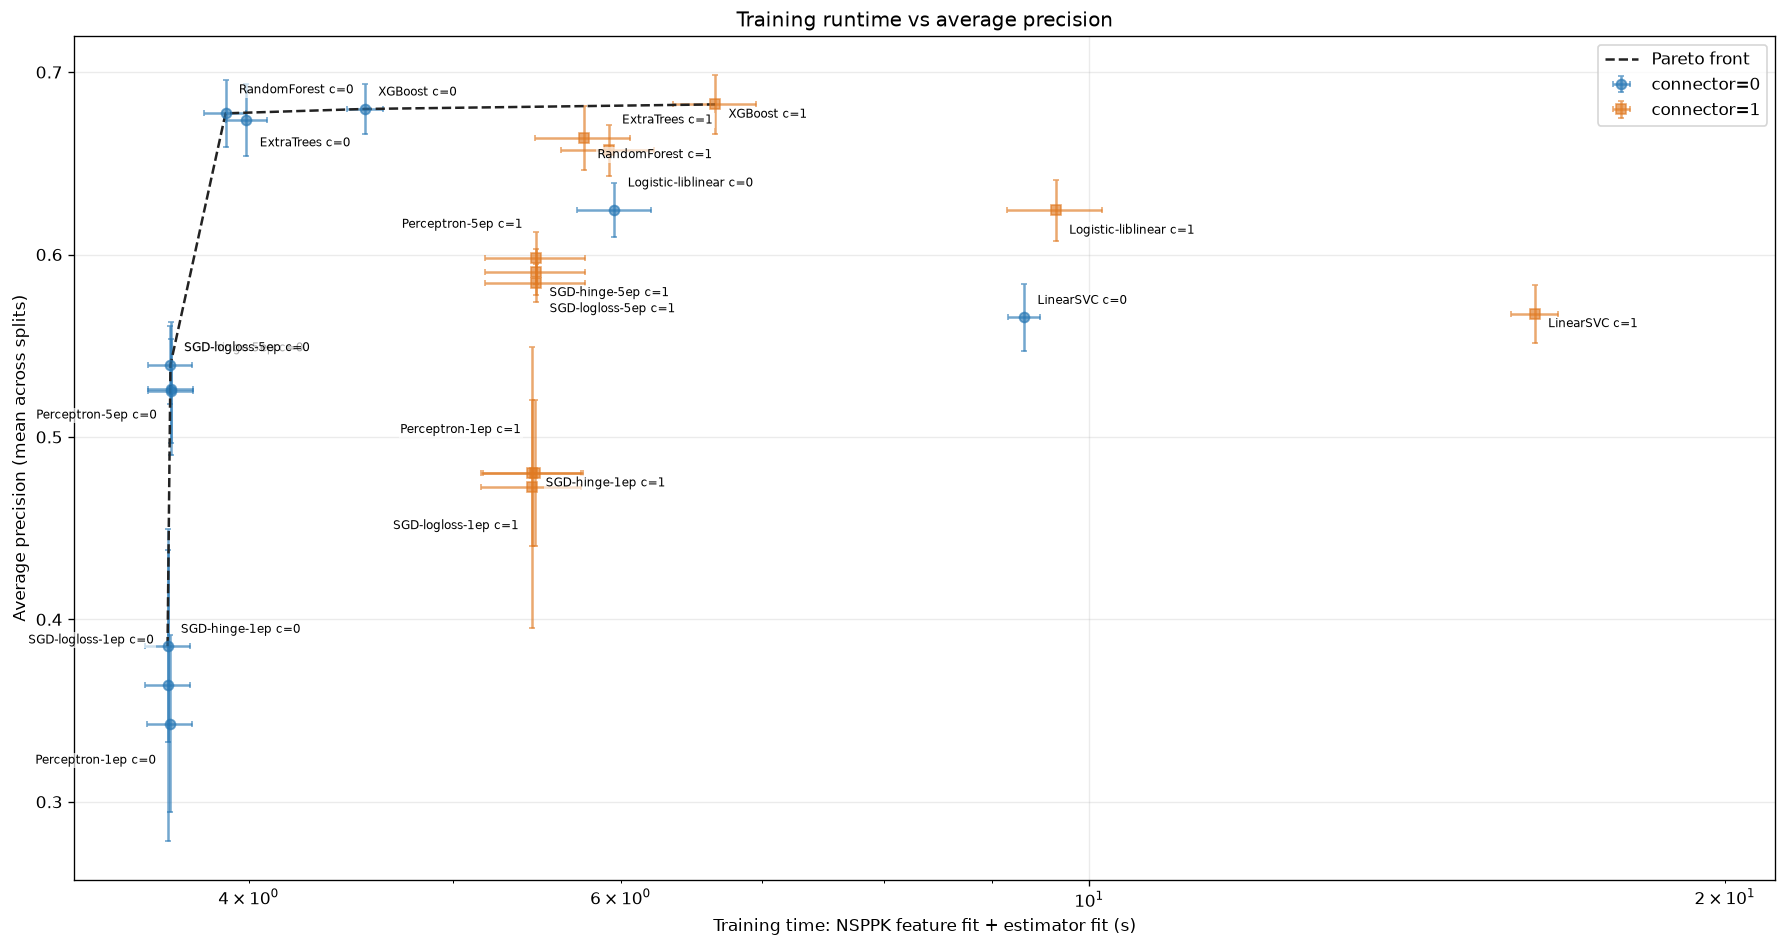

,connector,estimator,train_seconds,average_precision,on_pareto_front
6,0,SGD-hinge-1ep,3.6615,0.3853,True
7,0,SGD-hinge-5ep,3.6732,0.5396,True
5,0,RandomForest,3.9006,0.6774,True
10,0,XGBoost,4.5404,0.6798,True
21,1,XGBoost,6.6514,0.6823,True
8,0,SGD-logloss-1ep,3.6617,0.3639,False
3,0,Perceptron-1ep,3.6703,0.3428,False
4,0,Perceptron-5ep,3.6737,0.5265,False
9,0,SGD-logloss-5ep,3.6749,0.5251,False
0,0,ExtraTrees,3.9902,0.6739,False


In [8]:
# Combine feature-generation and estimator fit times for end-to-end training cost.
fit_summary = results_df.groupby(["connector", "estimator"]).agg(
    estimator_fit_seconds=("fit_seconds", "mean"),
    estimator_fit_std=("fit_seconds", "std"),
    average_precision=("average_precision", "mean"),
    average_precision_std=("average_precision", "std"),
).reset_index()
feature_summary = feature_timings_df.groupby("connector").agg(
    feature_fit_seconds=("feature_fit_seconds", "mean"),
    feature_fit_std=("feature_fit_seconds", "std"),
).reset_index()
pareto_df = fit_summary.merge(feature_summary, on="connector")
pareto_df["train_seconds"] = (
    pareto_df["feature_fit_seconds"] + pareto_df["estimator_fit_seconds"]
)
pareto_df["train_seconds_std"] = np.sqrt(
    pareto_df["feature_fit_std"].fillna(0) ** 2
    + pareto_df["estimator_fit_std"].fillna(0) ** 2
)

dominated = []
for index, point in pareto_df.iterrows():
    others = pareto_df.drop(index)
    is_dominated = (
        (others["train_seconds"] <= point["train_seconds"])
        & (others["average_precision"] >= point["average_precision"])
        & (
            (others["train_seconds"] < point["train_seconds"])
            | (others["average_precision"] > point["average_precision"])
        )
    ).any()
    dominated.append(is_dominated)
pareto_df["on_pareto_front"] = ~np.asarray(dominated)
frontier = pareto_df[pareto_df["on_pareto_front"]].sort_values("train_seconds")

fig, axis = plt.subplots(figsize=(15, 8))
connector_styles = {
    0: {"color": "#2878B5", "marker": "o"},
    1: {"color": "#E07A22", "marker": "s"},
}
for connector, style in connector_styles.items():
    points = pareto_df[pareto_df["connector"] == connector]
    axis.errorbar(
        points["train_seconds"],
        points["average_precision"],
        xerr=points["train_seconds_std"],
        yerr=points["average_precision_std"],
        fmt=style["marker"],
        color=style["color"],
        ecolor=style["color"],
        alpha=0.65,
        capsize=2,
        label=f"connector={connector}",
    )
axis.plot(
    frontier["train_seconds"],
    frontier["average_precision"],
    color="#222222",
    linestyle="--",
    linewidth=1.5,
    label="Pareto front",
)
label_offsets = {
    "Perceptron-1ep": (-8, -24),
    "SGD-hinge-1ep": (8, 8),
    "SGD-logloss-1ep": (-8, 25),
    "Perceptron-5ep": (-8, -18),
    "SGD-hinge-5ep": (8, 8),
    "SGD-logloss-5ep": (8, 24),
    "RandomForest": (8, 12),
    "ExtraTrees": (8, -16),
    "XGBoost": (8, 8),
    "Logistic-liblinear": (8, 14),
    "LinearSVC": (8, 8),
}
for _, point in pareto_df.iterrows():
    dx, dy = label_offsets[point["estimator"]]
    if point["connector"] == 1:
        dy = -dy
    axis.annotate(
        f"{point['estimator']} c={int(point['connector'])}",
        (point["train_seconds"], point["average_precision"]),
        xytext=(dx, dy),
        textcoords="offset points",
        ha="left" if dx > 0 else "right",
        fontsize=7,
        bbox={"facecolor": "white", "alpha": 0.65, "edgecolor": "none", "pad": 1},
    )

axis.set_xscale("log")
axis.set_xlim(right=pareto_df["train_seconds"].max() * 1.3)
axis.set_xlabel("Training time: NSPPK feature fit + estimator fit (s)")
axis.set_ylabel("Average precision (mean across splits)")
axis.set_title("Training runtime vs average precision")
axis.grid(alpha=0.25)
axis.legend()
plt.tight_layout()
plt.show()

pareto_df.sort_values(["on_pareto_front", "train_seconds"], ascending=[False, True])[
    ["connector", "estimator", "train_seconds", "average_precision", "on_pareto_front"]
].round(4)
